## Author: Gabriel Vance
## Class: DSC530 - Data Exporation and Analysis
## Professor: Matthew Metzger
## Date: May 17, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 9 & 10 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Regression, Classification, and Clustering Analysis.

In [79]:
# Standard libraries
import numpy as np
import pandas as pd

# Scikit-learn: Preprocessing and Modeling
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    fowlkes_mallows_score,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Custom utilities
from ml_utils.classification import confusion_matrix_visual, plot_roc


In [80]:
# Use this if you need to install the ml-utils package
# !pip install git+https://github.com/stefmolin/ml-utils.git

# Chapter 9, Exercise 1 - Clustering Model
## a. Combine the red and white wine datasets (data/winequality-red.csv and data/winequality-white.csv, respectively) and add a column for the kind of wine (red or white).


In [ ]:
# Read both csvs into pandas dataframes
red_df = pd.read_csv("winequality-red.csv")
white_df = pd.read_csv("winequality-white.csv")

# Add a column to indicate the type of wine
red_df['wine_type'] = 'red'
white_df['wine_type'] = 'white'

# Combine the datasets
wine_df = pd.concat([red_df, white_df], ignore_index=True)
wine_df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type,"fixed acidity;""volatile acidity"";""citric acid"";""residual sugar"";""chlorides"";""free sulfur dioxide"";""total sulfur dioxide"";""density"";""pH"";""sulphates"";""alcohol"";""quality"""
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5.0,red,NaN
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5.0,red,NaN
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5.0,red,NaN
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6.0,red,NaN
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5.0,red,NaN


# Chapter 9, Exercise 1 - Clustering Model
## c. Build and fit a pipeline that scales the data and then uses k-means clustering to make two clusters. Be sure not to use the quality column.


In [82]:

# Keep wine_type separately before stripping non-numeric data
wine_type = wine_df['wine_type']

# Keep only numeric columns and drop NaNs
wine_numeric_df = wine_df.select_dtypes(include=['number']).dropna()

# Filter wine_type to match numeric rows
wine_type_filtered = wine_type.loc[wine_numeric_df.index]

# Drop 'quality' for clustering
X = wine_numeric_df.drop(columns=['quality'])

# Build and fit the pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=2, random_state=42))
])
pipeline.fit(X)

Pipeline(steps=[('scaler', StandardScaler()),
                ('kmeans', KMeans(n_clusters=2, random_state=42))])

# Chapter 9, Exercise 1 - Clustering Model
## d. Use the Fowlkes-Mallows Index (the fowlkes_mallows_score() function is in sklearn.metrics) to evaluate how well k-means is able to make the distinction between red and white wine.


In [94]:
true_labels = (wine_type_filtered == 'white').astype(int).values
cluster_labels = pipeline.named_steps['kmeans'].labels_

fmi = fowlkes_mallows_score(true_labels, cluster_labels)
print(f"Fowlkes-Mallows: {fmi:.2f}")
# With an index of .73, the clustering is quite good. 1 would be perfect clustering, 0 would be random clustering.

Fowlkes-Mallows: 0.73


# Chapter 9, Exercise 1 - Clustering Model
## e. Find the center of each cluster.



In [96]:
# Get the cluster centers from the fitted KMeans model
# These are in standardized (z-score) space because the data was scaled before clustering
cluster_centers_scaled = pipeline.named_steps['kmeans'].cluster_centers_

# Transform the cluster centers back to the original feature space
# This allows us to interpret the centers using real-world values (e.g., alcohol %, acidity)
cluster_centers = pipeline.named_steps['scaler'].inverse_transform(cluster_centers_scaled)

# Convert the cluster centers into a DataFrame for easier inspection and readability
# Each row represents a cluster; each column corresponds to a feature in the original dataset
centers_df = pd.DataFrame(cluster_centers, columns=X.columns)

# Display the cluster centers in the original feature space
# This helps us understand the characteristics of each cluster
print(centers_df)


   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0       9.922712          0.413907     0.462881        2.765763   0.099900   
1       7.382260          0.594430     0.158761        2.406095   0.080196   

   free sulfur dioxide  total sulfur dioxide   density        pH  sulphates  \
0            13.410169             39.388136  0.997689  3.201847   0.748237   
1            17.316155             50.607532  0.996195  3.375005   0.605471   

     alcohol  
0  10.607401  
1  10.315147  


# Chapter 9, Exercise 2 Predict star temperature
## a. Using the data/stars.csv file, perform some initial EDA and then build a linear regression model of all the numeric columns to predict the temperature of the star.


In [98]:
# Load the stars dataset from a CSV file into a pandas DataFrame
stars_df = pd.read_csv("stars.csv")

# Perform initial exploratory data analysis (EDA)
# - .info() shows data types, non-null counts, and memory usage
# - .describe() provides summary statistics for numeric columns
# - .head() shows the first 5 rows of the dataset
print(stars_df.info())
print(stars_df.describe())
print(stars_df.head())

# Identify all numeric columns in the dataset
# We'll use these for regression, but exclude 'temperature' since it's the target variable
numeric_cols = stars_df.select_dtypes(include='number').columns
feature_cols = [col for col in numeric_cols if col != 'temperature']

# Separate the input features (X) and target variable (y)
X_stars = stars_df[feature_cols]
y_stars = stars_df['temperature']

# Drop rows that contain missing values in either X or y
# This ensures the model is trained only on complete data
X_stars = X_stars.copy()
y_stars = y_stars.copy()
valid_idx = X_stars.notna().all(axis=1) & y_stars.notna()  # mask for rows without NaNs
X_stars = X_stars[valid_idx]
y_stars = y_stars[valid_idx]

# Initialize and fit a linear regression model using the cleaned data
linreg = LinearRegression()
linreg.fit(X_stars, y_stars)  # Model learns coefficients to best predict 'temperature'


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3183 entries, 0 to 3182
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   temperature   2793 non-null   float64
 1   magV          1274 non-null   float64
 2   mass          3090 non-null   float64
 3   spectraltype  1206 non-null   object 
 4   magJ          1563 non-null   float64
 5   radius        2721 non-null   float64
 6   magB          1003 non-null   float64
 7   magH          1556 non-null   float64
 8   magK          1585 non-null   float64
 9   metallicity   2411 non-null   float64
 10  name          3183 non-null   object 
 11  planets       3183 non-null   float64
dtypes: float64(10), object(2)
memory usage: 298.5+ KB
None
        temperature         magV         mass         magJ       radius  \
count   2793.000000  1274.000000  3090.000000  1563.000000  2721.000000   
mean    5532.146084    10.304334     0.960175     9.899493     1.605091   
std   

LinearRegression()

# Chapter 9, Exercise 2 Predict star temperature
## b. Train the model on 75% of the initial data.


In [100]:

# Split the data into 75% train and 25% test
X_train, X_test, y_train, y_test = train_test_split(X_stars, y_stars, test_size=0.25, random_state=42)

# Fit the linear regression model on the training data
linreg.fit(X_train, y_train)

LinearRegression()

# Chapter 9, Exercise 2 Predict star temperature
## c. Calculate the R2 and RMSE of the model.

In [ ]:
# Predict on the test set
y_pred = linreg.predict(X_test)

# Calculate R2 score
r2 = r2_score(y_test, y_pred)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R2 Score: {r2:.4f}")
print(f"RMSE: {rmse:.2f}")

# 417 is a bit high, but when we consider that the temp is for stars (which is several thousand degrees), it makes sense.

R2 Score: 0.8022
RMSE: 417.19


# Chapter 9, Exercise 2 Predict star temperature
## d. Find the coefficients for each regressor and the intercept of the linear regression equation.


In [102]:
# Get the coefficients and intercept from the trained linear regression model
coefficients = linreg.coef_
intercept = linreg.intercept_

# Display coefficients with their corresponding feature names
for feature, coef in zip(X_train.columns, coefficients):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {intercept:.4f}")

magV: -187.3272
mass: 176.1549
magJ: -962.3455
radius: 7.7733
magB: -301.0361
magH: -11.1359
magK: 1504.5034
metallicity: 22.2633
planets: -27.9314
Intercept: 6627.0539


# Chapter 9, Exercise 3 Classify planets that have shorter years than Earth
## a. Using the data/planets.csv file, build a logistic regression model with the eccentricity, semimajoraxis, and mass columns as regressors. You will need to make a new column to use for the y (year shorter than Earth).



In [103]:

planets_df = pd.read_csv("planets.csv")
# Drop rows with missing values in required columns
planets_clean = planets_df.dropna(subset=['eccentricity', 'semimajoraxis', 'mass', 'period'])

# Create target: 1 if period < 365.25 (shorter year than Earth), else 0
planets_clean['shorter_year'] = (planets_clean['period'] < 365.25).astype(int)

# Select features and target
X_planets = planets_clean[['eccentricity', 'semimajoraxis', 'mass']]
y_planets = planets_clean['shorter_year']

# Build and fit logistic regression model
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_planets, y_planets)

C:\Users\Gabe\AppData\Local\Temp\ipykernel_49356\261531681.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  planets_clean['shorter_year'] = (planets_clean['period'] < 365.25).astype(int)


LogisticRegression(max_iter=1000)

# Chapter 9, Exercise 3 Classify planets that have shorter years than Earth
## b. Find the accuracy score.



In [104]:

# Predict the labels for the training data
y_pred_planets = logreg.predict(X_planets)

# Calculate accuracy score
accuracy = accuracy_score(y_planets, y_pred_planets)
print(f"Accuracy Score: {accuracy:.4f}")

Accuracy Score: 0.9763


# Chapter 9, Exercise 3 Classify planets that have shorter years than Earth
## c. Use the classification_report() function from scikit-learn to see the precision, recall, and F1 score for each class.




In [105]:

# Generate and print the classification report
print(classification_report(y_planets, y_pred_planets, target_names=['Longer or equal year', 'Shorter year']))

                      precision    recall  f1-score   support

Longer or equal year       0.96      0.97      0.96       400
        Shorter year       0.98      0.98      0.98       822

            accuracy                           0.98      1222
           macro avg       0.97      0.97      0.97      1222
        weighted avg       0.98      0.98      0.98      1222



# Chapter 9, Exercise 3 Classify planets that have shorter years than Earth
## d. With the plot_roc() function from the ml_utils.classification module, plot the ROC curve.




<Axes: title={'center': 'ROC curve'}, xlabel='False Positive Rate (FPR)', ylabel='True Positive Rate (TPR)'>

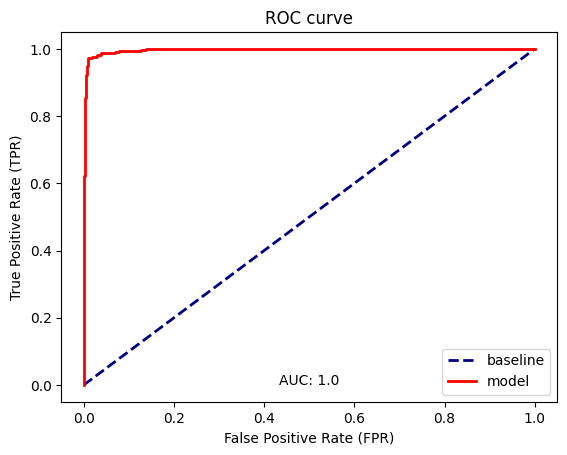

In [106]:

# Plot the ROC curve for the logistic regression model
y_probs = logreg.predict_proba(X_planets)[:, 1]

# Now plot ROC using true labels and predicted probabilities
plot_roc(y_planets, y_probs)

# Chapter 9, Exercise 3 Classify planets that have shorter years than Earth
## e. Create a confusion matrix using the confusion_matrix_visual() function from the ml_utils.classification module.





<Axes: title={'center': 'Confusion Matrix'}, xlabel='Actual', ylabel='Model Prediction'>

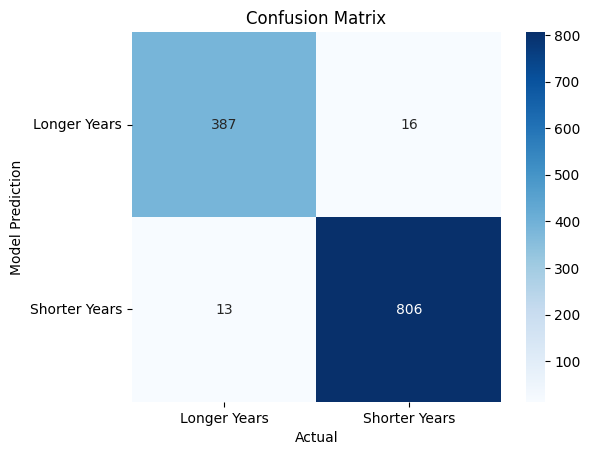

In [107]:

# Plot the confusion matrix for the logistic regression model
class_labels = ['Longer Years', 'Shorter Years']
confusion_matrix_visual(y_planets, y_pred_planets, class_labels)